In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt
import random

In [ ]:
drive.mount('/content/drive')
wines = pd.read_csv('/content/drive/My Drive/wines.csv')
wines.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
X = wines.drop(columns=['quality','Id'])
y = wines['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = MinMaxScaler()
X_train_normalized = scaler.fit_transform(X_train)
X_test_normalized = scaler.transform(X_test)

print("X_train shape:", X_train_normalized.shape)
print("X_test shape:", X_test_normalized.shape)

X_train shape: (914, 11)
X_test shape: (229, 11)


In [ ]:
model = Sequential([
    Input(shape=(X_train_normalized.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='linear')
])
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.fit(X_train_normalized, y_train, epochs=5)
model.evaluate(X_test_normalized, y_test, verbose=2)

Epoch 1/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 31.8667 - mae: 5.5779   
Epoch 2/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 20.7120 - mae: 4.4616 
Epoch 3/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 8.8842 - mae: 2.8191  
Epoch 4/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.1148 - mae: 1.2163 
Epoch 5/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1422 - mae: 0.8415 
8/8 - 0s - 20ms/step - loss: 0.7591 - mae: 0.6818


[0.759125292301178, 0.6817806363105774]

## find optimal number of neurons

In [ ]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

def build_and_evaluate_model(units):
    model = Sequential([
        Input(shape=(X_train_normalized.shape[1],)),
        Dense(units, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='linear')
    ])
    model.compile(
        optimizer='adam',
        loss='mean_squared_error',
        metrics=['mae']
    )
    history = model.fit(X_train_normalized, y_train, epochs=5, validation_data=(X_test_normalized, y_test), verbose=0)
    val_mae = history.history['val_mae'][-1]
    return val_mae

# Initial number of units
units = 128
max_units = 512
best_units = units
best_val_mae = build_and_evaluate_model(units)

# Doubling or halving loop
while units < max_units:
    new_units = units * 2
    if new_units > max_units:
        break
    new_val_mae = build_and_evaluate_model(new_units)
    if new_val_mae < best_val_mae:
        best_val_mae = new_val_mae
        best_units = new_units
        units = new_units  # Update units to continue searching upward
    else:  # halving only if doubling does not improve
        new_units = units // 2
        if new_units < 1:
            break
        new_val_mae = build_and_evaluate_model(new_units)
        if new_val_mae < best_val_mae:
            best_val_mae = new_val_mae
            best_units = new_units
            units = new_units  # Update units to continue searching downward
        else:
            break  # if neither improves performance

print(f"The optimal number of units found is: {best_units} with a validation MAE of: {best_val_mae:.4f}")

The optimal number of units found is: 512 with a validation MAE of: 0.6342


Since the search of number of neurons reaches the maximum number of neurons, it suggests that the model is not performing as desired.  Therefore, an additional layer is added to achieve better result and enhance computational efficiency.

In [ ]:
# Set the random seed for reproducibility
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

def build_and_evaluate_model(units):
    model = Sequential([
        Input(shape=(X_train_normalized.shape[1],)),
        Dense(512, activation='relu'), #set the number of neurons in first layer to 512
        Dropout(0.2),
        Dense(units, activation='relu'),
        Dense(1, activation='linear')
    ])
    model.compile(
        optimizer='adam',
        loss='mean_squared_error',
        metrics=['mae']
    )
    history = model.fit(X_train_normalized, y_train, epochs=5, validation_data=(X_test_normalized, y_test), verbose=0)
    val_mae = history.history['val_mae'][-1]
    return val_mae

units = 128
max_units = 1024
best_units = units
best_val_mae = build_and_evaluate_model(units)

while units < max_units:
    new_units = units * 2
    if new_units > max_units:
        break
    new_val_mae = build_and_evaluate_model(new_units)
    if new_val_mae < best_val_mae:
        best_val_mae = new_val_mae
        best_units = new_units
        units = new_units
    else:
        new_units = units // 2
        if new_units < 1:
            break
        new_val_mae = build_and_evaluate_model(new_units)
        if new_val_mae < best_val_mae:
            best_val_mae = new_val_mae
            best_units = new_units
            units = new_units
        else:
            break

print(f"The optimal number of units in second layer found is: {best_units} with a validation MAE of: {best_val_mae:.4f}")

The optimal number of units in second layer found is: 128 with a validation MAE of: 0.5470


## Find optimal dropout rate and learning rate

In [ ]:
def build_model(hp):
    model = Sequential([
        Input(shape=(X_train_normalized.shape[1],)),
        Dense(512, activation='relu'),
        Dropout(hp.Float('dropout', min_value=0, max_value=0.5, step=0.05)),  # Tune first dropout rate
        Dense(128, activation='relu'),
        Dropout(hp.Float('dropout_2', min_value=0, max_value=0.5, step=0.05)),  # Tune second dropout rate
        Dense(1, activation='linear')
    ])

    model.compile(
        optimizer=Adam(learning_rate=hp.Choice('learning_rate', values=[0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05])),
        loss='mean_squared_error',
        metrics=['mae']
    )
    return model

tuner = kt.RandomSearch(
    build_model,
    objective='val_mae',
    max_trials=50,
    directory='new_fresh_dir',
    project_name='dropout_lr_tuning_new'
)
tuner.search(X_train_normalized, y_train, epochs=5, validation_data=(X_test_normalized, y_test), verbose=1)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"The optimal first dropout rate is: {best_hps.get('dropout')}")
print(f"The optimal second dropout rate is: {best_hps.get('dropout_2')}")
print(f"The optimal learning rate is: {best_hps.get('learning_rate')}")

Trial 50 Complete [00h 00m 05s]
val_mae: 0.579840362071991

Best val_mae So Far: 0.4722539186477661
Total elapsed time: 00h 05m 06s
The optimal first dropout rate is: 0.2
The optimal second dropout rate is: 0.1
The optimal learning rate is: 0.05


## Testing epochs

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
def build_and_train_model(X_train, y_train, X_val, y_val):
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(512, activation='relu'),
        Dropout(0.2),
        Dense(128, activation='relu'),
        Dropout(0.1),
        Dense(1, activation='linear')
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.05),
        loss='mean_squared_error',
        metrics=['mae']
    )
    # Early stopping callback
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )
    history = model.fit(
        X_train_normalized, y_train,
        epochs=50,
        validation_data=(X_val, y_val),
        callbacks=[early_stopping],
        verbose=1
    )
    optimal_epochs = len(history.history['mae'])
    print(f"The optimal number of epochs is: {optimal_epochs}")
    # Evaluate the model on the validation set
    val_loss, val_mae = model.evaluate(X_val, y_val, verbose=2)
    print(f"Validation loss: {val_loss}, Validation MAE: {val_mae}")

    return model, optimal_epochs

model, optimal_epochs = build_and_train_model(X_train_normalized, y_train, X_test_normalized, y_test)

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 43.6077 - mae: 4.5258 - val_loss: 4.4793 - val_mae: 1.9209
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 3.7435 - mae: 1.5473 - val_loss: 1.3616 - val_mae: 1.0283
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.5429 - mae: 0.9966 - val_loss: 0.4637 - val_mae: 0.5295
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.1025 - mae: 0.8407 - val_loss: 0.6262 - val_mae: 0.6043
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.2373 - mae: 0.8906 - val_loss: 0.4238 - val_mae: 0.4936
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 1.1777 - mae: 0.8662 - val_loss: 0.5039 - val_mae: 0.5690
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.0427 - mae: 0.8174 - val_loss: 0.3838 - val_mae: 0.4741
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7410 - mae: 0.6638 - val_loss: 0.3858 - val_mae: 0.4755
Epoch 9/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6380 

The function outputs optimal number of epochs ranging from 8 to 11 through multiple trials, with 10 epochs being the most frequent results.

## Testing the hyperparamter

In [ ]:
model2 = Sequential([
    Input(shape=(X_train_normalized.shape[1],)),
    Dense(512, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.1),
    Dense(1, activation='linear')
])
model2.compile(
    optimizer=Adam(learning_rate=0.05),
    loss='mean_squared_error',
    metrics=['mae']
)

model2.fit(X_train_normalized, y_train, epochs=10)
model2.evaluate(X_test_normalized, y_test, verbose=2)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 31.4949 - mae: 4.6012
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.8568 - mae: 1.0992
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.5175 - mae: 0.9745
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1224 - mae: 0.8108
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1150 - mae: 0.8318
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.1081 - mae: 0.8092
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9775 - mae: 0.7799
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7424 - mae: 0.6836
Epoch 9/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7178 - mae: 0.6607
Epoch 10/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6989 - mae: 0.6506
8/8 - 0s - 29ms/step - loss: 0.5266 - mae: 0.5696


[0.526645302772522, 0.5696413516998291]

The model outputs test mae ranging from 0.4718 to 0.5195, validation mae around 0.62

In [ ]:
random_indices = np.random.choice(len(X_test_normalized), size=3, replace=False)

X_illustrative = X_test_normalized[random_indices]  # random three entries
y_actual =  y_test.iloc[:3].to_numpy()  # actual wine quality

predictions = model2.predict(X_illustrative)

for i in range(len(X_illustrative)):
    print(f"Input: {X_illustrative[i]}\n",
          f"Predicted Quality: {predictions[i]}\n",
          f"Actual Quality: {y_actual[i]}\n")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Input: [0.21818182 0.39041096 0.07       0.10958904 0.13188648 0.20895522
 0.05514706 0.43031226 0.50393701 0.16167665 0.51785714]
 Predicted Quality: [5.297018]
 Actual Quality: 5

Input: [0.62727273 0.20547945 0.48       0.11643836 0.10851419 0.10447761
 0.05147059 0.64356436 0.27559055 0.11976048 0.46428571]
 Predicted Quality: [5.5416594]
 Actual Quality: 6

Input: [0.4        0.2260274  0.49       0.11643836 0.12020033 0.29850746
 0.25367647 0.65727342 0.48031496 0.14371257 0.23214286]
 Predicted Quality: [5.0030346]
 Actual Quality: 5



8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


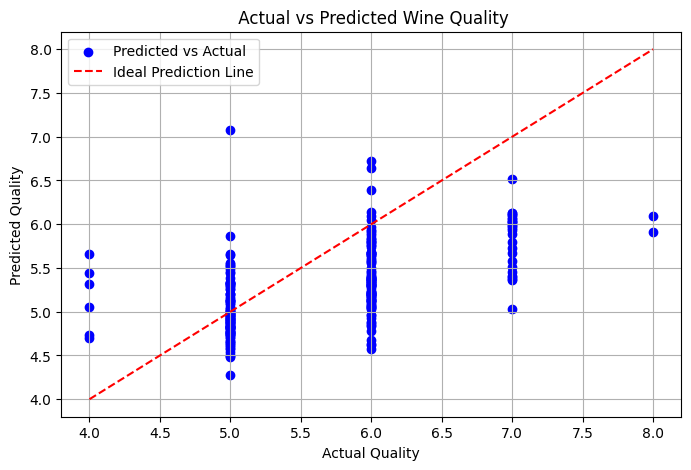

In [ ]:

import matplotlib.pyplot as plt
predictions = model2.predict(X_test_normalized)

num_samples = min(len(predictions), 500)
y_actual_subset = y_test[:num_samples].to_numpy()
predicted_quality_subset = [pred[0] for pred in predictions[:num_samples]]

plt.figure(figsize=(8, 5))
plt.scatter(y_actual_subset, predicted_quality_subset, color='blue', label='Predicted vs Actual')
plt.plot([min(y_actual_subset), max(y_actual_subset)], [min(y_actual_subset), max(y_actual_subset)], 'r--', label='Ideal Prediction Line')
plt.xlabel('Actual Quality')
plt.ylabel('Predicted Quality')
plt.title(' Actual vs Predicted Wine Quality')
plt.legend()
plt.grid(True)
plt.show()